# Zadanie domowe -- interpolacja dwusześcienna

Interpolacja dwusześcienna, to podobnie jak w przypadku interpolacji dwuliniowej, rozszerzenie idei interpolacji jednowymiarowej na dwuwymiarową siatkę.
W trakcie jej obliczania wykorzystywane jest 16 pikseli z otoczenia (dla dwuliniowej 4).
Skutkuje to zwykle lepszymi wynikami - obraz wyjściowy jest bardziej gładki i z mniejszą liczbą artefaktów.
Ceną jest znaczny wzrost złożoności obliczeniowej (zostało to zaobserwowane podczas ćwiczenia).

Interpolacja dana jest wzorem:
\begin{equation}
I(i,j) = \sum_{i=0}^{3} \sum_{j=0}^{3} a_{ij} x^i y^j
\end{equation}

Zadanie sprowadza się zatem do wyznaczenia 16 współczynników $a_{ij}$.
W tym celu wykorzystuje się, oprócz wartość w puntach $A$ (0,0), $B$ (1 0), $C$ (1,1), $D$ (0,1) (por. rysunek dotyczący interpolacji dwuliniowej), także pochodne cząstkowe $A_x$, $A_y$, $A_{xy}$.
Pozwala to rozwiązać układ 16-tu równań.

Jeśli zgrupujemy parametry $a_{ij}$:
\begin{equation}
a = [ a_{00}~a_{10}~a_{20}~a_{30}~a_{01}~a_{11}~a_{21}~a_{31}~a_{02}~a_{12}~a_{22}~a_{32}~a_{03}~a_{13}~a_{23}~a_{33}]
\end{equation}

i przyjmiemy:
\begin{equation}
x = [A~B~D~C~A_x~B_x~D_x~C_x~A_y~B_y~D_y~C_y~A_{xy}~B_{xy}~D_{xy}~C_{xy}]^T
\end{equation}

To zagadnienie można opisać w postaci równania liniowego:
\begin{equation}
Aa = x
\end{equation}
gdzie macierz $A^{-1}$ dana jest wzorem:

\begin{equation}
A^{-1} =
\begin{bmatrix}
1& 0& 0& 0& 0& 0& 0& 0& 0& 0& 0& 0& 0& 0& 0& 0 \\
0&  0&  0&  0&  1&  0&  0&  0&  0&  0&  0&  0&  0&  0&  0&  0 \\
-3&  3&  0&  0& -2& -1&  0&  0&  0&  0&  0&  0&  0&  0&  0&  0 \\
2& -2&  0&  0&  1&  1&  0&  0&  0&  0&  0&  0&  0&  0&  0&  0 \\
0&  0&  0&  0&  0&  0&  0&  0&  1&  0&  0&  0&  0&  0&  0&  0 \\
0&  0&  0&  0&  0&  0&  0&  0&  0&  0&  0&  0&  1&  0&  0&  0 \\
0&  0&  0&  0&  0&  0&  0&  0& -3&  3&  0&  0& -2& -1&  0&  0 \\
0&  0&  0&  0&  0&  0&  0&  0&  2& -2&  0&  0&  1&  1&  0&  0 \\
-3&  0&  3&  0&  0&  0&  0&  0& -2&  0& -1&  0&  0&  0&  0&  0 \\
0&  0&  0&  0& -3&  0&  3&  0&  0&  0&  0&  0& -2&  0& -1&  0 \\
9& -9& -9&  9&  6&  3& -6& -3&  6& -6&  3& -3&  4&  2&  2&  1 \\
-6&  6&  6& -6& -3& -3&  3&  3& -4&  4& -2&  2& -2& -2& -1& -1 \\
2&  0& -2&  0&  0&  0&  0&  0&  1&  0&  1&  0&  0&  0&  0&  0 \\
0&  0&  0&  0&  2&  0& -2&  0&  0&  0&  0&  0&  1&  0&  1&  0 \\
-6&  6&  6& -6& -4& -2&  4&  2& -3&  3& -3&  3& -2& -1& -2& -1 \\
4& -4& -4&  4&  2&  2& -2& -2&  2& -2&  2& -2&  1&  1&  1&  1 \\
\end{bmatrix}
\end{equation}

Potrzebne w rozważaniach pochodne cząstkowe obliczane są wg. następującego przybliżenia (przykład dla punktu A):
\begin{equation}
A_x = \frac{I(i+1,j) - I(i-1,j)}{2}
\end{equation}
\begin{equation}
A_y = \frac{I(i,j+1) - I(i,j-1)}{2}
\end{equation}
\begin{equation}
A_{xy} = \frac{I(i+1,j+1) - I(i-1,j) - I(i,j-1) + I(i,j)}{4}
\end{equation}

## Zadanie

Wykorzystując podane informacje zaimplementuj interpolację dwusześcienną.
Uwagi:
- macierz $A^{-1}$ dostępna jest w pliku *a_invert.py*
- trzeba się zastanowić nad potencjalnym wykraczaniem poza zakres obrazka (jak zwykle).

Ponadto dokonaj porównania liczby operacji arytmetycznych i dostępów do pamięci koniecznych przy realizacji obu metod interpolacji: dwuliniowej i dwusześciennej.

Używamy macierzy z pliku `ainvert.py`
Funkcje poniżej przyjmują obraz w skali szarości typu `uint8` oraz dodatnie skale:
najpierw w pionie, potem w poziomie. W tablicy `image[y, x]` pierwszy indeks oznacza wiersz.

In [ ]:
import cv2
import sys
import requests
import numpy as np
from pathlib import Path
from matplotlib import pyplot as plt

folder = Path("lab5") if Path("lab5").is_dir() else Path(".")
url = "https://raw.githubusercontent.com/vision-agh/poc_sw/master/05_Resolution/"
for name in ["ainvert.py", "parrot.bmp", "clock.bmp", "chessboard.bmp"]:
    path = folder / name
    if not path.exists():
        response = requests.get(url + name, timeout=30)
        response.raise_for_status()
        path.write_bytes(response.content)

sys.path.insert(0, str(folder.resolve()))
from ainvert import A_invert

parrot = cv2.imread(str(folder / "parrot.bmp"), cv2.IMREAD_GRAYSCALE)
clock = cv2.imread(str(folder / "clock.bmp"), cv2.IMREAD_GRAYSCALE)
chessboard = cv2.imread(str(folder / "chessboard.bmp"), cv2.IMREAD_GRAYSCALE)

### Interpolacja dwusześcienna

Dla każdego piksela wyniku wyznaczamy położenie w oryginale, cztery narożniki
i ich pochodne. Wektor ma kolejność z zadania: wartości A, B, D, C, potem
pochodne po x, po y oraz mieszane. Mnożenie przez `A_invert` daje 16 współczynników.

In [ ]:
def bicubic(image, h_scale, w_scale):
    height, width = image.shape
    new_height = max(1, round(height * h_scale))
    new_width = max(1, round(width * w_scale))
    result = np.zeros((new_height, new_width), dtype=np.uint8)
    src = image.astype(float)

    padded = np.pad(src, 1, mode="edge")
    fx = (padded[1:-1, 2:] - padded[1:-1, :-2]) / 2
    fy = (padded[2:, 1:-1] - padded[:-2, 1:-1]) / 2
    fxy = (padded[2:, 2:] - padded[2:, :-2] - padded[:-2, 2:] + padded[:-2, :-2]) / 4 # pochodne

    sy = new_height / height
    sx = new_width / width
    for y in range(new_height):
        for x in range(new_width):
            src_y = min(max((y + 0.5) / sy - 0.5, 0), height - 1)
            src_x = min(max((x + 0.5) / sx - 0.5, 0), width - 1)
            
            y0, x0 = int(np.floor(src_y)), int(np.floor(src_x))
            y1, x1 = min(y0 + 1, height - 1), min(x0 + 1, width - 1)
            
            dy, dx = src_y - y0, src_x - x0

            # każda grupa zawiera kolejno A, B, D, C
            values = []
            for field in [src, fx, fy, fxy]:
                values.extend([field[y0, x0], field[y0, x1],
                               field[y1, x0], field[y1, x1]])
            a = A_invert @ np.array(values)

            dx2, dy2 = dx * dx, dy * dy
            px = np.array([1, dx, dx2, dx2 * dx])
            py = np.array([1, dy, dy2, dy2 * dy])
            value = py @ a.reshape(4, 4) @ px

            result[y, x] = np.clip(round(value), 0, 255)
    return result

`px` i `py` zawierają potęgi współrzędnych lokalnych: $1,t,t^2,t^3$.
Ostatnie mnożenie oblicza wielomian z zadania.
Bikubiczna interpolacja może dać wartości poza zakresem 0–255, dlatego wynik
zaokrąglamy i ograniczamy przez `np.clip`.

### Interpolacja dwuliniowa do porównania

Tutaj wystarczą cztery wartości. Najpierw interpolujemy dwa wiersze, a potem wynik w pionie.
Stosujemy to samo przeliczanie środków pikseli i to samo zachowanie na brzegu.

In [3]:
def bilinear(image, h_scale, w_scale):
    height, width = image.shape
    new_height = max(1, round(height * h_scale))
    new_width = max(1, round(width * w_scale))
    result = np.zeros((new_height, new_width), dtype=np.uint8)
    sy, sx = new_height / height, new_width / width
    for y in range(new_height):
        for x in range(new_width):
            src_y = min(max((y + 0.5) / sy - 0.5, 0), height - 1)
            src_x = min(max((x + 0.5) / sx - 0.5, 0), width - 1)
            y0, x0 = int(np.floor(src_y)), int(np.floor(src_x))
            y1, x1 = min(y0 + 1, height - 1), min(x0 + 1, width - 1)
            dy, dx = src_y - y0, src_x - x0
            wx, wy = 1 - dx, 1 - dy
            top = wx * float(image[y0, x0]) + dx * float(image[y0, x1])
            bottom = wx * float(image[y1, x0]) + dx * float(image[y1, x1])
            result[y, x] = round(wy * top + dy * bottom)
    return result

### Przykłady

In [4]:
def compare(image, h_scale, w_scale):
    linear = bilinear(image, h_scale, w_scale)
    cubic = bicubic(image, h_scale, w_scale)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, result, title in zip(axes, [image, linear, cubic],
                                 ["Oryginał", "Dwuliniowa", "Dwusześcienna"]):
        ax.imshow(result, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"{title}: {result.shape[1]} × {result.shape[0]} px")
        ax.axis("off")
    fig.suptitle(f"Skala y={h_scale}, x={w_scale}")
    plt.tight_layout()
    plt.show()

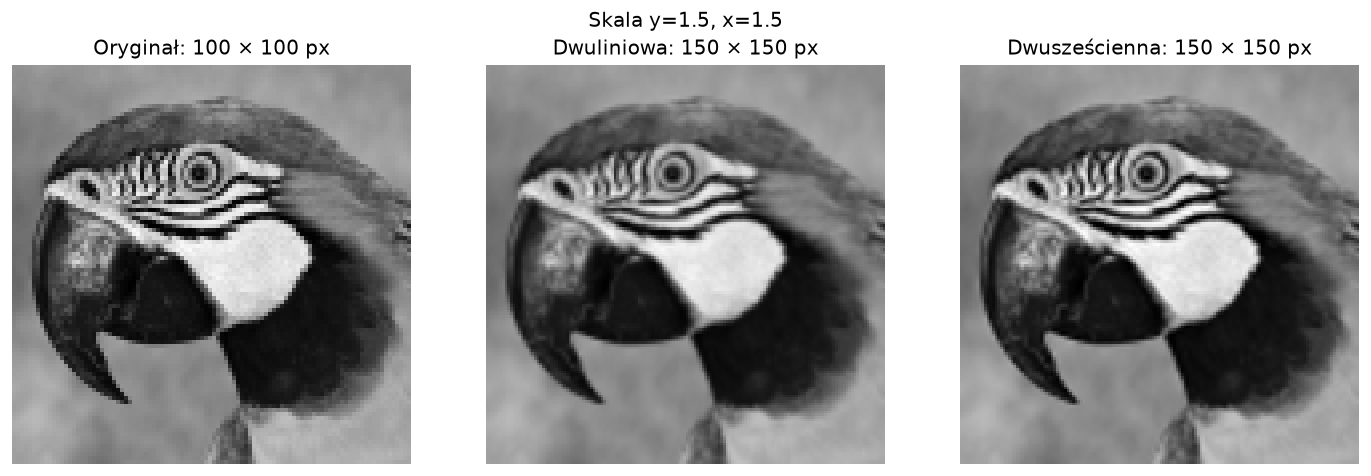

In [5]:
# Papuga: powiększenie 1.5 × 1.5
compare(parrot, 1.5, 1.5)

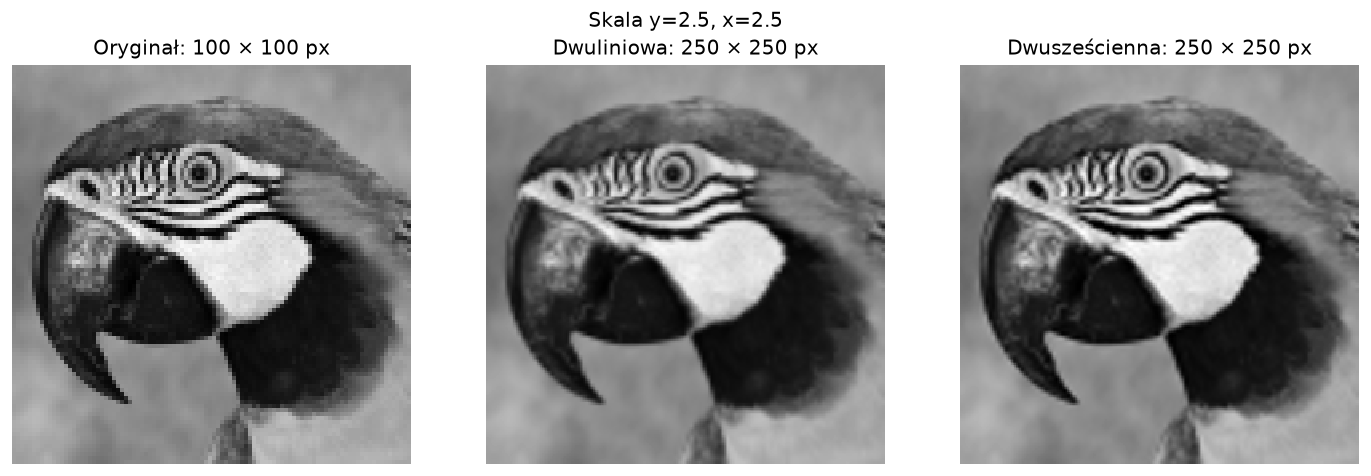

In [6]:
# Papuga: powiększenie 2.5 × 2.5
compare(parrot, 2.5, 2.5)

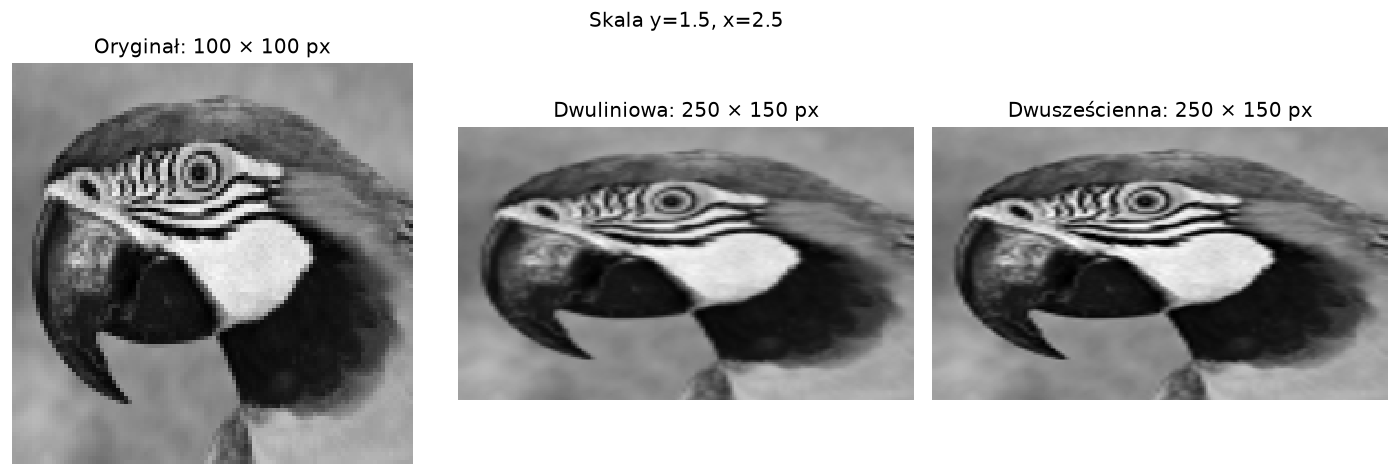

In [7]:
# Papuga: różne skale
compare(parrot, 1.5, 2.5)

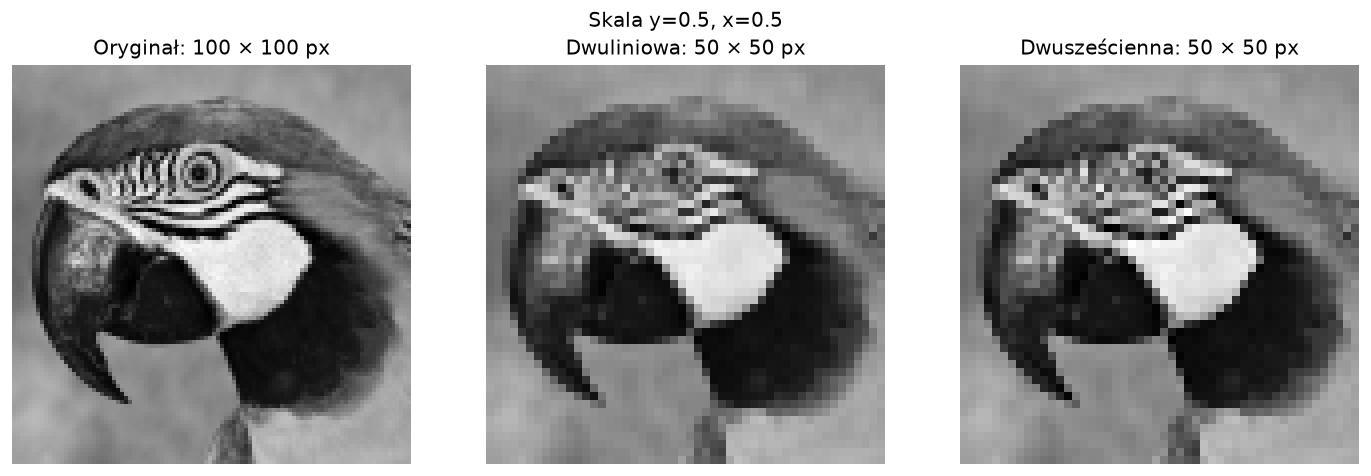

In [8]:
# Papuga: pomniejszenie
compare(parrot, 0.5, 0.5)

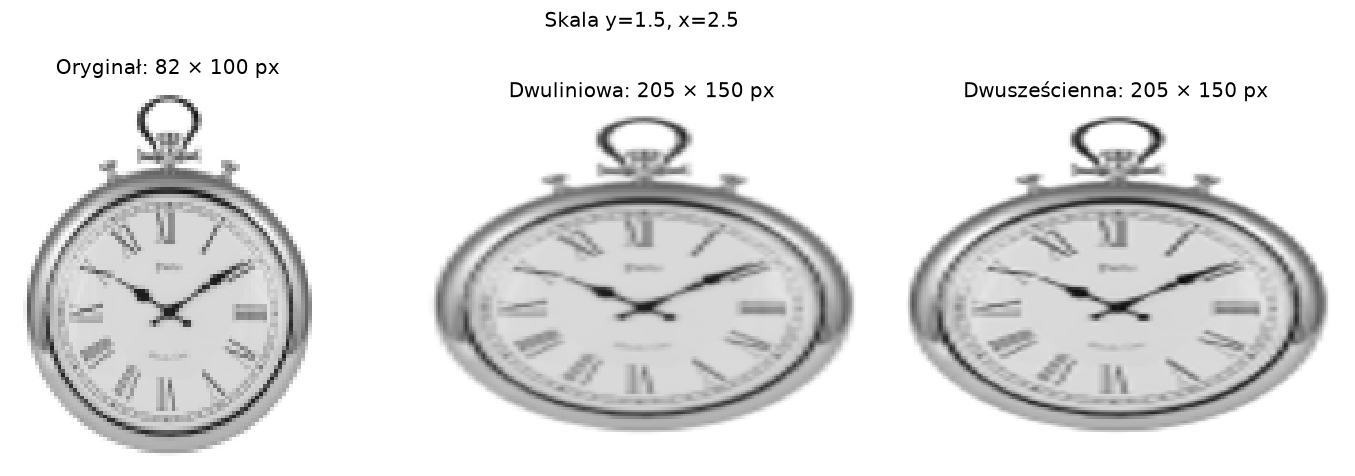

In [9]:
# Zegar: obraz prostokątny
compare(clock, 1.5, 2.5)

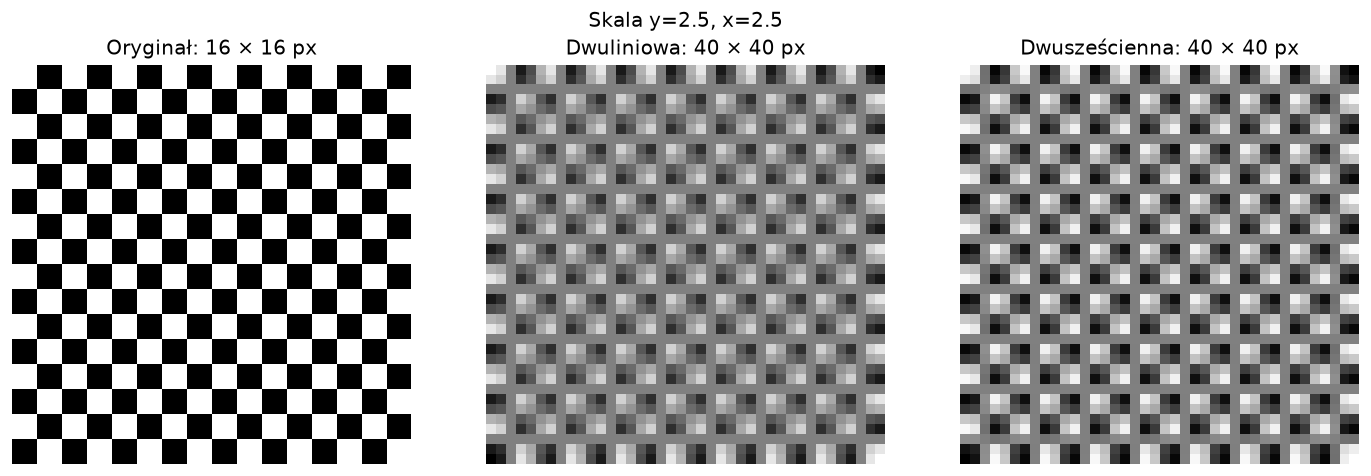

In [10]:
# Szachownica: ostre krawędzie
compare(chessboard, 2.5, 2.5)

**Obserwacje:** obie metody wygładzają powiększony obraz. Dwusześcienna zwykle lepiej
zachowuje ostrość szczegółów niż dwuliniowa, ale przy mocnych kontrastach może tworzyć
obwódki. Na szachownicy widać nowe szarości przy granicach pól.
Większa liczba obliczeń nie zawsze oznacza korzystniejszy wygląd.
Przy pomniejszaniu tracimy szczegóły; ta implementacja nie zawiera filtru antyaliasingowego.

### Porównanie complexity

Dwuliniowa korzysta z 4 sąsiednich pikseli, a dwusześcienna z 16.

W mojej implementacji obliczenie jednego piksela wymaga:
- dwuliniowa: 11 operacji arytmetycznych i 4 odczyty z obrazu,
- dwusześcienna: 535 operacji oraz 16 odczytów — 4 wartości obrazu i 12 pochodnych.

Pomijam tutaj obliczanie współrzędnych i wcześniejsze przygotowanie pochodnych. Większość kosztu metody dwusześciennej wynika z mnożenia macierzy 16 × 16 przez wektor.

Dwusześcienna potrzebuje też pamięci na trzy tablice pochodnych i macierz `A_invert`. Jest więc droższa obliczeniowo i pamięciowo.